# Yellow Sigatoka XGBoost

Train and validate XGBoost using the approved features and existing splits. The reserved test split is not loaded.

## 1. Import Libraries

In [1]:
# Import libraries
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

sns.set_theme(style="whitegrid")


## 2. Load Data

Use only the existing training and validation datasets and the saved Random Forest metadata.

In [2]:
# Load the data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "datasets" / "yellow_sigatoka"
train_df = pd.read_csv(DATA_DIR / "YS_SIMULATED_train.csv")
validation_df = pd.read_csv(DATA_DIR / "YS_SIMULATED_validation.csv")

RF_METADATA_PATH = PROJECT_ROOT / "Models" / "yellow_sigatoka" / "random_forest" / "random_forest_metadata.json"
with RF_METADATA_PATH.open(encoding="utf-8") as metadata_file:
    rf_metadata = json.load(metadata_file)

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Random Forest validation results:", rf_metadata["validation_regression_metrics"])


Training rows: 4200
Validation rows: 900
Random Forest validation results: {'mae': 0.5640128074074025, 'rmse': 1.0117282843325812, 'r2': 0.9989195315312797}


## 3. Select Features

Use the same three features and feature order as the Random Forest model.

In [3]:
# Select model inputs
FEATURES = [
    "mean_temp_previous_14d_c",
    "wet_hours_previous_14d",
    "consecutive_wetness_hours",
]
TARGET = "risk_score"

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_validation = validation_df[FEATURES]
y_validation = validation_df[TARGET]

print("Training inputs:", X_train.shape)
print("Validation inputs:", X_validation.shape)
print("Feature order:", list(X_train.columns))


Training inputs: (4200, 3)
Validation inputs: (900, 3)
Feature order: ['mean_temp_previous_14d_c', 'wet_hours_previous_14d', 'consecutive_wetness_hours']


## 4. Train XGBoost

XGBoost adds decision trees sequentially, with later trees working to reduce earlier prediction errors.

In [4]:
# Train XGBoost baseline
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## 5. Make Predictions

In [5]:
# Predict risk scores
baseline_predictions = xgb_model.predict(X_validation)
print("Raw baseline prediction minimum:", baseline_predictions.min())
print("Raw baseline prediction maximum:", baseline_predictions.max())
print("Baseline predictions outside 0 to 100:", int(((baseline_predictions < 0) | (baseline_predictions > 100)).sum()))


Raw baseline prediction minimum: -1.606586
Raw baseline prediction maximum: 97.32707
Baseline predictions outside 0 to 100: 31


## 6. Evaluate Model

Use raw predictions for regression metrics. RMSE is the square root of MSE.

,MAE,RMSE,R2
Baseline XGBoost,1.1344,1.5801,0.9974


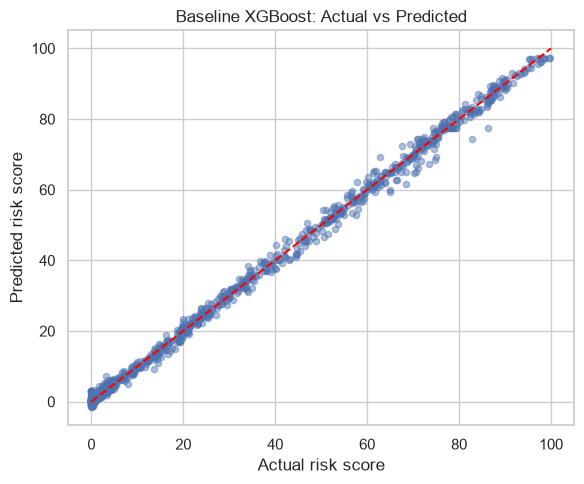

In [6]:
# Check validation results
baseline_metrics = {
    "MAE": mean_absolute_error(y_validation, baseline_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_validation, baseline_predictions)),
    "R2": r2_score(y_validation, baseline_predictions),
}
display(pd.DataFrame([baseline_metrics], index=["Baseline XGBoost"]).round(4))

plt.figure(figsize=(6, 5))
plt.scatter(y_validation, baseline_predictions, alpha=0.45, s=20)
plt.plot([0, 100], [0, 100], color="red", linestyle="--")
plt.xlabel("Actual risk score")
plt.ylabel("Predicted risk score")
plt.title("Baseline XGBoost: Actual vs Predicted")
plt.tight_layout()
plt.show()


## 7. Compare Model Settings

Compare the four requested settings and select the one with the lowest validation MAE.

In [7]:
# Compare the models
model_settings = [
    ("Baseline", 100, 3, 0.10),
    ("Model 2", 200, 3, 0.05),
    ("Model 3", 200, 5, 0.05),
    ("Model 4", 300, 5, 0.05),
]

models = {"Baseline": xgb_model}
predictions = {"Baseline": baseline_predictions}
comparison_rows = []

for name, tree_count, depth, rate in model_settings:
    if name == "Baseline":
        model = xgb_model
        prediction = baseline_predictions
    else:
        model = XGBRegressor(
            n_estimators=tree_count,
            max_depth=depth,
            learning_rate=rate,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1,
        )
        model.fit(X_train, y_train)
        prediction = model.predict(X_validation)

    models[name] = model
    predictions[name] = prediction
    comparison_rows.append({
        "Setting": name,
        "Trees": tree_count,
        "Depth": depth,
        "Learning rate": rate,
        "MAE": mean_absolute_error(y_validation, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_validation, prediction)),
        "R2": r2_score(y_validation, prediction),
    })

comparison_table = pd.DataFrame(comparison_rows).set_index("Setting")
display(comparison_table.round(5))

best_setting = comparison_table["MAE"].idxmin()
selected_model = models[best_setting]
selected_predictions = predictions[best_setting]
selected_metrics = comparison_table.loc[best_setting]
raw_min = float(selected_predictions.min())
raw_max = float(selected_predictions.max())
outside_prediction_count = int(((selected_predictions < 0) | (selected_predictions > 100)).sum())
print("Selected setting:", best_setting)
print("Raw prediction range:", raw_min, "to", raw_max)
print("Raw predictions outside 0 to 100:", outside_prediction_count)


,Trees,Depth,Learning rate,MAE,RMSE,R2
Setting,,,,,,
Baseline,100,3,0.10,1.13436,1.58009,0.99736
Model 2,200,3,0.05,1.14136,1.64078,0.99716
Model 3,200,5,0.05,0.56397,0.87410,0.99919
Model 4,300,5,0.05,0.50093,0.76876,0.99938


Selected setting: Model 4
Raw prediction range: -0.5724944472312927 to 98.96258544921875
Raw predictions outside 0 to 100: 21


## 8. Risk Level Predictions

Clip a separate prediction copy only for category conversion. The regression metrics continue to use raw predictions.

Accuracy: 0.9833
Macro F1: 0.9833
              precision    recall  f1-score   support

     No Risk       0.97      0.99      0.98       225
         Low       0.98      0.96      0.97       225
    Moderate       0.98      1.00      0.99       225
        High       1.00      1.00      1.00       225

    accuracy                           0.98       900
   macro avg       0.98      0.98      0.98       900
weighted avg       0.98      0.98      0.98       900



,No Risk,Low,Moderate,High
No Risk,222,3,0,0
Low,6,215,4,0
Moderate,0,1,224,0
High,0,0,1,224


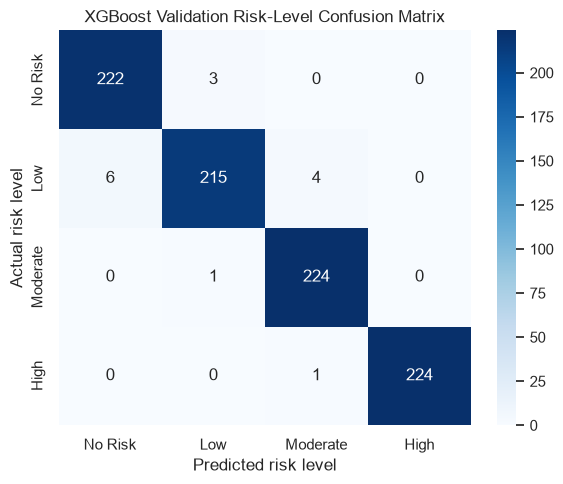

Misclassified records: 15
Misclassified rows' distance to nearest score threshold - median: 0.15200000000000102


In [8]:
# Convert predictions to risk levels
risk_labels = ["No Risk", "Low", "Moderate", "High"]
risk_thresholds = {
    "No Risk": "score < 5",
    "Low": "5 <= score < 30",
    "Moderate": "30 <= score < 65",
    "High": "65 <= score <= 100",
}
clipped_predictions = np.clip(selected_predictions.copy(), 0, 100)
predicted_levels = pd.cut(
    clipped_predictions,
    bins=[-np.inf, 5, 30, 65, np.inf],
    right=False,
    labels=risk_labels,
)
actual_levels = validation_df["risk_level"]

risk_accuracy = accuracy_score(actual_levels, predicted_levels)
risk_macro_f1 = f1_score(actual_levels, predicted_levels, average="macro")
classification_results = classification_report(
    actual_levels, predicted_levels, labels=risk_labels, output_dict=True, zero_division=0
)
print("Accuracy:", round(risk_accuracy, 4))
print("Macro F1:", round(risk_macro_f1, 4))
print(classification_report(actual_levels, predicted_levels, labels=risk_labels, zero_division=0))

confusion = confusion_matrix(actual_levels, predicted_levels, labels=risk_labels)
confusion_table = pd.DataFrame(confusion, index=risk_labels, columns=risk_labels)
display(confusion_table)
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_table, annot=True, fmt="d", cmap="Blues")
plt.title("XGBoost Validation Risk-Level Confusion Matrix")
plt.xlabel("Predicted risk level")
plt.ylabel("Actual risk level")
plt.tight_layout()
plt.show()

incorrect = np.asarray(actual_levels.astype(str)) != np.asarray(predicted_levels.astype(str))
threshold_distances = np.min(np.abs(y_validation.to_numpy()[:, None] - np.array([5, 30, 65])), axis=1)
print("Misclassified records:", int(incorrect.sum()))
print("Misclassified rows' distance to nearest score threshold - median:", float(np.median(threshold_distances[incorrect])) if incorrect.any() else 0.0)


## 9. Compare with Random Forest

Compare models on the same validation split. Validation MAE is the primary criterion; classification and deployment measures are secondary.

In [9]:
# Compare XGBoost with Random Forest and the original formula
rf_regression = rf_metadata["validation_regression_metrics"]
rf_classification = rf_metadata["validation_risk_level_metrics"]

T14 = X_validation["mean_temp_previous_14d_c"].to_numpy(dtype=float)
LW14 = X_validation["wet_hours_previous_14d"].to_numpy(dtype=float)
C = X_validation["consecutive_wetness_hours"].to_numpy(dtype=float)
TempSuit = np.clip(np.where(T14 <= 25, (T14 - 8) / 17, (37.5 - T14) / 12.5), 0, 1)
WetAnchor = np.where((T14 > 21) & (T14 <= 25), 130, 160)
WetSuit = np.clip((LW14 - 30) / (WetAnchor + 45 - 30), 0, 1)
Continuity = np.clip(C / 18, 0, 1)
formula_predictions = np.round(np.clip(100 * TempSuit * (0.88 * WetSuit + 0.12 * Continuity), 0, 100), 3)
formula_mae = mean_absolute_error(y_validation, formula_predictions)
formula_rmse = np.sqrt(mean_squared_error(y_validation, formula_predictions))

model_comparison = pd.DataFrame([
    {"Metric": "MAE", "Random Forest": rf_regression["mae"], "XGBoost": float(selected_metrics["MAE"]), "Formula": formula_mae},
    {"Metric": "RMSE", "Random Forest": rf_regression["rmse"], "XGBoost": float(selected_metrics["RMSE"]), "Formula": formula_rmse},
    {"Metric": "R2", "Random Forest": rf_regression["r2"], "XGBoost": float(selected_metrics["R2"]), "Formula": r2_score(y_validation, formula_predictions)},
    {"Metric": "Risk-level accuracy", "Random Forest": rf_classification["accuracy"], "XGBoost": float(risk_accuracy), "Formula": np.nan},
    {"Metric": "Macro F1", "Random Forest": rf_classification["macro_f1"], "XGBoost": float(risk_macro_f1), "Formula": np.nan},
]).set_index("Metric")
display(model_comparison.round(5))
print("The score formula generated the synthetic targets, so its validation errors should be nearly zero.")


,Random Forest,XGBoost,Formula
Metric,,,
MAE,0.56401,0.50093,0.00102
RMSE,1.01173,0.76876,0.00150
R2,0.99892,0.99938,1.00000
Risk-level accuracy,0.97667,0.98333,NaN
Macro F1,0.97666,0.98329,NaN


The score formula generated the synthetic targets, so its validation errors should be nearly zero.


## 10. Model Size and Prediction Time

Measure one prediction pass over all 900 validation rows after training. This is a laptop measurement, not a Raspberry Pi benchmark.

In [10]:
# Measure validation prediction time
start_time = time.perf_counter()
timed_predictions = selected_model.predict(X_validation)
prediction_time_seconds = time.perf_counter() - start_time
print("Prediction time for 900 rows (seconds):", prediction_time_seconds)
print("Timed predictions match the selected validation predictions:", bool(np.allclose(timed_predictions, selected_predictions)))


Prediction time for 900 rows (seconds): 0.007257499964907765
Timed predictions match the selected validation predictions: True


## 11. Save Model

Save only the selected XGBoost model and its metadata. Reload it and verify it predicts the validation rows.

In [11]:
# Save the model
MODEL_DIR = PROJECT_ROOT / "Models" / "yellow_sigatoka" / "xgboost"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "xgboost_model.joblib"
metadata_path = MODEL_DIR / "xgboost_metadata.json"
joblib.dump(selected_model, model_path)
model_size_mib = model_path.stat().st_size / (1024 ** 2)

selected_parameters = {
    "n_estimators": int(selected_model.n_estimators),
    "max_depth": int(selected_model.max_depth),
    "learning_rate": float(selected_model.learning_rate),
    "objective": selected_model.objective,
    "random_state": int(selected_model.random_state),
    "n_jobs": int(selected_model.n_jobs),
}
metadata = {
    "features": FEATURES,
    "target": TARGET,
    "selected_setting": best_setting,
    "parameters": selected_parameters,
    "validation_metrics": {
        "mae": float(selected_metrics["MAE"]),
        "rmse": float(selected_metrics["RMSE"]),
        "r2": float(selected_metrics["R2"]),
        "risk_level_accuracy": float(risk_accuracy),
        "risk_level_macro_f1": float(risk_macro_f1),
    },
    "risk_thresholds": risk_thresholds,
    "model_size_mib": float(model_size_mib),
    "validation_prediction_time_seconds": float(prediction_time_seconds),
    "limitation": "Targets are project-defined synthetic environmental suitability scores, not measured disease outcomes.",
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

loaded_model = joblib.load(model_path)
loaded_predictions = loaded_model.predict(X_validation)
print("Saved XGBoost model size (MiB):", round(model_size_mib, 4))
print("Reloaded model prediction rows:", len(loaded_predictions))
print("Reload check passed:", len(loaded_predictions) == len(validation_df) and np.allclose(loaded_predictions, selected_predictions))
print("Saved model:", model_path)
print("Saved metadata:", metadata_path)


Saved XGBoost model size (MiB): 0.7706
Reloaded model prediction rows: 900
Reload check passed: True
Saved model: C:\Users\HP\Desktop\ML training\Models\yellow_sigatoka\xgboost\xgboost_model.joblib
Saved metadata: C:\Users\HP\Desktop\ML training\Models\yellow_sigatoka\xgboost\xgboost_metadata.json


## 12. Training Summary

Validation results compare models on synthetic scores. They do not establish performance on measured disease outcomes.

In [12]:
# Save the XGBoost report
report_path = PROJECT_ROOT / "reports" / "yellow_sigatoka" / "xgboost" / "XGBoost_Training_Report.md"
report_path.parent.mkdir(parents=True, exist_ok=True)

setting_lines = ["| Setting | Trees | Depth | Learning rate | MAE | RMSE | R2 |", "|---|---:|---:|---:|---:|---:|---:|"]
for setting, row in comparison_table.iterrows():
    setting_lines.append(f"| {setting} | {int(row['Trees'])} | {int(row['Depth'])} | {row['Learning rate']:.2f} | {row['MAE']:.5f} | {row['RMSE']:.5f} | {row['R2']:.5f} |")

class_lines = ["| Risk level | Precision | Recall | F1-score | Support |", "|---|---:|---:|---:|---:|"]
for label in risk_labels:
    row = classification_results[label]
    class_lines.append(f"| {label} | {row['precision']:.4f} | {row['recall']:.4f} | {row['f1-score']:.4f} | {int(row['support'])} |")
confusion_lines = ["| Actual \ Predicted | " + " | ".join(risk_labels) + " |", "|---|" + "---:|" * len(risk_labels)]
for label, row in zip(risk_labels, confusion):
    confusion_lines.append("| " + label + " | " + " | ".join(str(int(value)) for value in row) + " |")

comparison_lines = ["| Metric | Random Forest | XGBoost | Formula |", "|---|---:|---:|---:|"]
for metric, row in model_comparison.iterrows():
    formula_value = "-" if pd.isna(row["Formula"]) else f"{row['Formula']:.5f}"
    if metric in ["Risk-level accuracy", "Macro F1"]:
        comparison_lines.append(f"| {metric} | {row['Random Forest']:.4f} | {row['XGBoost']:.4f} | {formula_value} |")
    else:
        comparison_lines.append(f"| {metric} | {row['Random Forest']:.5f} | {row['XGBoost']:.5f} | {formula_value} |")

adjacent_errors = int(incorrect.sum())
nearest_threshold_median = float(np.median(threshold_distances[incorrect])) if incorrect.any() else 0.0
rf_wins_mae = float(selected_metrics["MAE"]) < float(rf_regression["mae"])
recommended_model = "XGBoost" if rf_wins_mae else "Random Forest"

report_lines = [
    "# Yellow Sigatoka XGBoost Training Report", "",
    "## Dataset and features",
    f"- Training: {len(train_df):,} rows; validation: {len(validation_df):,} rows. Existing splits were preserved.",
    "- Inputs: `mean_temp_previous_14d_c`, `wet_hours_previous_14d`, `consecutive_wetness_hours`; target: `risk_score`.", "",
    "## Four XGBoost settings",
    *setting_lines, "",
    f"Selected by lowest validation MAE: **{best_setting}**.",
    f"Selected validation results: MAE {selected_metrics['MAE']:.5f}, RMSE {selected_metrics['RMSE']:.5f}, R2 {selected_metrics['R2']:.5f}.",
    f"Raw prediction range: {raw_min:.5f} to {raw_max:.5f}; values outside 0 to 100: {outside_prediction_count}.", "",
    "## Risk-level validation",
    f"Accuracy {risk_accuracy:.4f}; macro F1 {risk_macro_f1:.4f}.",
    *class_lines, "", *confusion_lines, "",
    f"Misclassified validation rows: {adjacent_errors}; median distance of their actual scores to the nearest threshold: {nearest_threshold_median:.3f} points. Errors are mostly adjacent category confusions; see the confusion matrix above.", "",
    "## Comparison on the same validation set",
    *comparison_lines, "",
    f"XGBoost has the lower validation MAE among the two ML models: **{recommended_model}**. This is a validation-based recommendation, not a final test-set conclusion. The scoring formula is much closer because it generated the synthetic targets.", "",
    "## Model size and prediction time",
    f"- Selected XGBoost joblib file: {model_size_mib:.4f} MiB.",
    f"- One prediction pass over 900 validation rows: {prediction_time_seconds:.6f} seconds on this machine; this is not a Raspberry Pi benchmark.",
    "- The saved model was reloaded and successfully predicted all validation rows.", "",
    "## Saved artifacts",
    f"- Model: `{model_path.relative_to(PROJECT_ROOT).as_posix()}`.",
    f"- Metadata: `{metadata_path.relative_to(PROJECT_ROOT).as_posix()}`.", "",
    "## Limitations and next step",
    "The target is a project-defined environmental suitability score, not confirmed infection probability or observed disease severity. Model metrics measure imitation of the synthetic formula, not real plantation prediction. NASA source windows may overlap across simulated scenarios. Compare the models and formula on validation, then use the reserved test set only for the planned final evaluation.",
]
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("Saved report:", report_path)
print("Validation-MAE recommendation between ML models:", recommended_model)


Saved report: C:\Users\HP\Desktop\ML training\reports\yellow_sigatoka\xgboost\XGBoost_Training_Report.md
Validation-MAE recommendation between ML models: XGBoost


<>:13: SyntaxWarning: invalid escape sequence '\ '
<>:13: SyntaxWarning: invalid escape sequence '\ '
C:\Users\HP\AppData\Local\Temp\ipykernel_33396\2864611701.py:13: SyntaxWarning: invalid escape sequence '\ '
  confusion_lines = ["| Actual \ Predicted | " + " | ".join(risk_labels) + " |", "|---|" + "---:|" * len(risk_labels)]
